In [2]:
#Load the Libraries
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lit, count, avg, broadcast, round as spark_round
from pyspark.sql.types import StructType, StructField, IntegerType, StringType
import os
import sys
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [3]:
# Initialize Spark Session for distributed metadata analysis

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

# Initialize Spark Session with Windows local binding configurations
spark = SparkSession.builder \
    .appName("ImageRecognitionPOE") \
    .master("local[*]") \
    .config("spark.driver.host", "127.0.0.1") \
    .getOrCreate()

print(f"Spark Version Active: {spark.version}")

Spark Version Active: 4.2.0


In [4]:
# Load CIFAR-10 dataset using TensorFlow and split into 50,000 training and 10,000 test samples.
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = datasets.cifar10.load_data()

print(f"Training Data Shape: {X_train_raw.shape}")  # Expected: (50000, 32, 32, 3)
print(f"Testing Data Shape: {X_test_raw.shape}")    # Expected: (10000, 32, 32, 3)
print('\nTraining data =', round(100*X_train_raw.shape[0] / (X_train_raw.shape[0] + X_test_raw.shape[0]),2),"% of total data")
print('\nTesting data =', round(100*X_test_raw.shape[0] / (X_train_raw.shape[0] + X_test_raw.shape[0]),2),"% of total data")

Training Data Shape: (50000, 32, 32, 3)
Testing Data Shape: (10000, 32, 32, 3)

Training data = 83.33 % of total data

Testing data = 16.67 % of total data


In [5]:
#Analyse the labels
Labels = np.unique(y_train_raw)
NumberofLabels = len(Labels)
print('\nLabels : ', Labels)
print('\nTotal number of labels : ', NumberofLabels)


Labels :  [0 1 2 3 4 5 6 7 8 9]

Total number of labels :  10


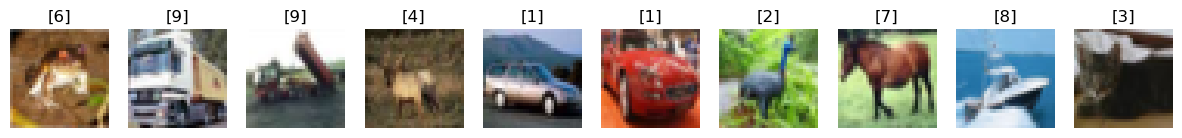

In [6]:
# Show a few images
n=10
plt.figure(figsize=(15,15))
for i in range(n):
    plt.subplot(1,n, i+1)
    plt.imshow(X_train_raw[i])
    plt.title("{}".format(y_train_raw[i]))
    plt.axis('off')
plt.show()

In [7]:
# Create a Spark DataFrame out of image metadata/labels to satisfy the Spark requirement
train_labels_flat = [int(val[0]) for val in y_train_raw]
spark_metadata_df = spark.createDataFrame(
    zip(range(len(train_labels_flat)), train_labels_flat), 
    ["image_id", "label_class"]
)

## Advanced Spark EDA: Broadcast Join, Spark SQL & Partition Inspection

In [9]:
# Perform Exploratory Data Analysis (EDA) using Spark aggregation
print("--- Spark EDA: Class Distribution Analysis ---")
class_distribution = spark_metadata_df.groupBy("label_class") \
    .agg(count("image_id").alias("record_count")) \
    .orderBy("label_class")

class_distribution.show()

# Class mapping reference for CIFAR-10
cifar10_classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer', 
    'dog', 'frog', 'horse', 'ship', 'truck'
]

--- Spark EDA: Class Distribution Analysis ---
+-----------+------------+
|label_class|record_count|
+-----------+------------+
|          0|        5000|
|          1|        5000|
|          2|        5000|
|          3|        5000|
|          4|        5000|
|          5|        5000|
|          6|        5000|
|          7|        5000|
|          8|        5000|
|          9|        5000|
+-----------+------------+



In [14]:
# Define CIFAR-10 class mapping as a Spark DataFrame
class_mapping_data = [
    (0, 'airplane'), (1, 'automobile'), (2, 'bird'), (3, 'cat'), (4, 'deer'),
    (5, 'dog'), (6, 'frog'), (7, 'horse'), (8, 'ship'), (9, 'truck')
]

schema = StructType([
    StructField("label_class", IntegerType(), True),
    StructField("class_name", StringType(), True)
])

classes_df = spark.createDataFrame(class_mapping_data, schema)

# Join spark_metadata_df with classes_df using a Broadcast Join for optimization
enriched_metadata_df = spark_metadata_df.join(
    broadcast(classes_df), 
    on="label_class", 
    how="inner"
)

# Cache DataFrame for iterative analytical queries
enriched_metadata_df.cache()

DataFrame[label_class: bigint, image_id: bigint, class_name: string]

In [15]:
# ==========================================
# SPARK SQL AGGREGATIONS & ANALYTICS
# ==========================================

# Register temporary view for Spark SQL analysis
enriched_metadata_df.createOrReplaceTempView("cifar_metadata")

# Execute Spark SQL query for class distribution and percentage share
class_summary_sql = spark.sql("""
    SELECT 
        class_name, 
        label_class, 
        COUNT(image_id) AS sample_count,
        ROUND(COUNT(image_id) * 100.0 / (SELECT COUNT(*) FROM cifar_metadata), 2) AS percentage_share
    FROM cifar_metadata
    GROUP BY class_name, label_class
    ORDER BY label_class ASC
""")

print("--- Spark SQL Class Distribution Summary ---")
class_summary_sql.show(10, truncate=False)

--- Spark SQL Class Distribution Summary ---
+----------+-----------+------------+----------------+
|class_name|label_class|sample_count|percentage_share|
+----------+-----------+------------+----------------+
|airplane  |0          |5000        |10.00           |
|automobile|1          |5000        |10.00           |
|bird      |2          |5000        |10.00           |
|cat       |3          |5000        |10.00           |
|deer      |4          |5000        |10.00           |
|dog       |5          |5000        |10.00           |
|frog      |6          |5000        |10.00           |
|horse     |7          |5000        |10.00           |
|ship      |8          |5000        |10.00           |
|truck     |9          |5000        |10.00           |
+----------+-----------+------------+----------------+



In [16]:
# ==========================================
# SPARK DISTRIBUTED PROCESSING INSPECTION
# ==========================================

print(f"Default Parallelism / Partitions: {spark.sparkContext.defaultParallelism}")
print(f"Current Partition Count of Metadata DF: {enriched_metadata_df.rdd.getNumPartitions()}")

# Repartition for optimal parallel execution across worker nodes
optimized_metadata_df = enriched_metadata_df.repartition(4, "label_class")
print(f"Optimized Partition Count: {optimized_metadata_df.rdd.getNumPartitions()}")

Default Parallelism / Partitions: 12
Current Partition Count of Metadata DF: 12
Optimized Partition Count: 4


## Feature Normalisation

In [17]:
# 1. Feature Normalisation
# Raw pixel values range from [0, 255]. We normalize them to float values between [0, 1]
# to stabilize gradient descent and accelerate convergence during backpropagation.
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

print(f"Normalized Training Set Shape: {X_train.shape}")
print(f"Normalized Testing Set Shape: {X_test.shape}")
print(f"Pixel value range verified: Min={X_train.min()}, Max={X_train.max()}")

Normalized Training Set Shape: (50000, 32, 32, 3)
Normalized Testing Set Shape: (10000, 32, 32, 3)
Pixel value range verified: Min=0.0, Max=1.0


## Model Training

In [18]:
# MODEL CONSTRUCTION & TRAINING

# Define CNN Architecture
model = models.Sequential([
    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Fully Connected Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax') # 10 output classes for CIFAR-10
])

# Compile Model with Chosen Hyperparameters
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train Model (Initial Run - Epochs: 10, Batch Size: 64)
history_initial = model.fit(
    X_train, y_train_raw,
    epochs=10,
    batch_size=64,
    validation_split=0.2, # 80% train, 20% validation split
    verbose=1
)

C:\Users\Itumeleng.Tlhale\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 32, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 16, 16, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 16, 16, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16, 16, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         524,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 592,554 (2.26 MB)

 Trainable params: 591,914 (2.26 MB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 130ms/step - accuracy: 0.4748 - loss: 1.5391 - val_accuracy: 0.6144 - val_loss: 1.0948
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 128ms/step - accuracy: 0.6310 - loss: 1.0454 - val_accuracy: 0.6812 - val_loss: 0.9336
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 130ms/step - accuracy: 0.6830 - loss: 0.9126 - val_accuracy: 0.6591 - val_loss: 0.9616
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 130ms/step - accuracy: 0.7131 - loss: 0.8229 - val_accuracy: 0.7201 - val_loss: 0.7902
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.7311 - loss: 0.7644 - val_accuracy: 0.6751 - val_loss: 0.9474
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.7515 - loss: 0.7169 - val_accuracy: 0.7082 - val_loss: 0.8650
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 132ms/step - accuracy: 0.7638 - loss: 0.6729 - val_accuracy: 0.7632 - val_loss: 0.6951
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 107s 172ms/step - accuracy: 0.7813 - loss: 

## Accuracy and Loss Plots

In [20]:
#Prepare variables to plot
EPOCH=10
epochs = range(1, EPOCH + 1)

loss_training = model.history.history['loss']
loss_val = model.history.history['val_loss']
acc_training = model.history.history['accuracy']
acc_val = model.history.history['val_accuracy']

## Loss Vs Epochs

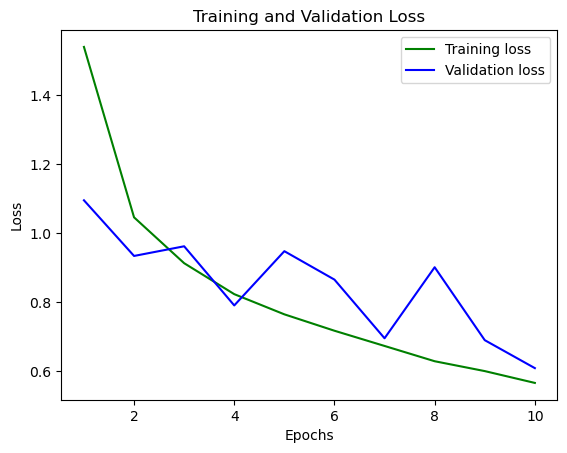

In [21]:
plt.plot(epochs, loss_training, 'g', label='Training loss')
plt.plot(epochs, loss_val, 'b', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Accuracy Vs Epochs 

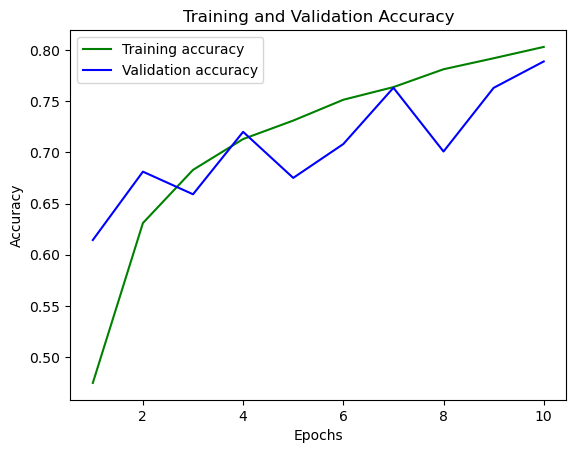

In [22]:
plt.plot(epochs, acc_training, 'g', label='Training accuracy')
plt.plot(epochs, acc_val, 'b', label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [23]:
# EVALUATION & INTERPRETATION

from sklearn.metrics import classification_report, confusion_matrix

# Evaluate on Unseen Test Data (10,000 records)
test_loss, test_acc = model.evaluate(X_test, y_test_raw, verbose=2)
print(f"\nInitial Model Test Accuracy: {test_acc * 100:.2f}%")
print(f"Initial Model Test Loss: {test_loss:.4f}")

# Generate Predictions for Detailed Classification Report
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report (Initial Model):")
print(classification_report(y_test_raw, y_pred, target_names=cifar10_classes))

313/313 - 5s - 15ms/step - accuracy: 0.7874 - loss: 0.6230

Initial Model Test Accuracy: 78.74%
Initial Model Test Loss: 0.6230
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step

Classification Report (Initial Model):
              precision    recall  f1-score   support

    airplane       0.81      0.83      0.82      1000
  automobile       0.85      0.93      0.89      1000
        bird       0.63      0.74      0.68      1000
         cat       0.67      0.57      0.62      1000
        deer       0.81      0.69      0.74      1000
         dog       0.76      0.68      0.71      1000
        frog       0.74      0.90      0.81      1000
       horse       0.86      0.81      0.84      1000
        ship       0.92      0.86      0.89      1000
       truck       0.85      0.87      0.86      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000



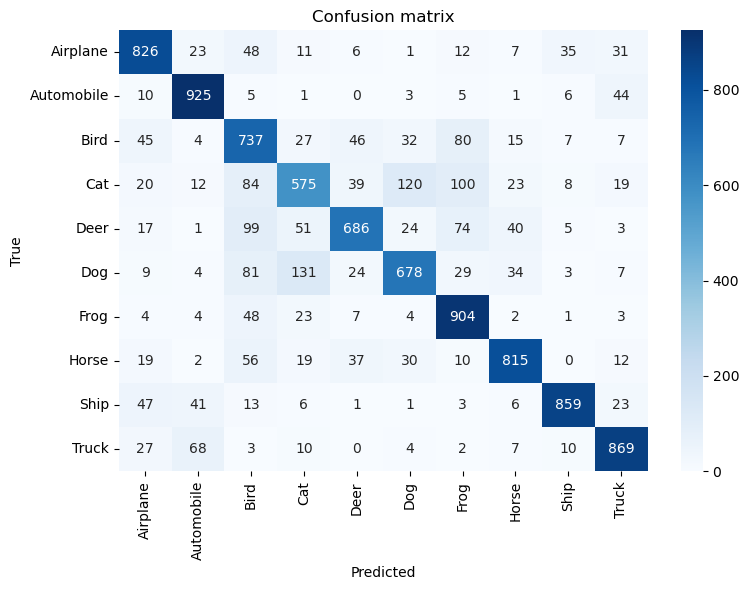

In [41]:
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
y_true = y_test_raw.ravel()

CLASS_NAMES = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

# Retraining & Hyperparameter Optimization 

In [25]:
# RETRAINING WITH ADJUSTED PARAMETERS

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Implement Data Augmentation to prevent overfitting
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)
datagen.fit(X_train)

In [26]:
# Compile a fresh instance of the model for retrained parameter comparison
model_retrained = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

# Use an explicit learning rate in Adam for finer optimization control
optimizer_tuned = tf.keras.optimizers.Adam(learning_rate=0.0008)

model_retrained.compile(
    optimizer=optimizer_tuned,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

C:\Users\Itumeleng.Tlhale\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
# Retrain using data augmentation generator (20 Epochs)
history_retrained = model_retrained.fit(
    datagen.flow(X_train, y_train_raw, batch_size=64),
    epochs=20,
    validation_data=(X_test, y_test_raw),
    verbose=1
)

Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 375s 470ms/step - accuracy: 0.4492 - loss: 1.6217 - val_accuracy: 0.4909 - val_loss: 1.5094
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 332s 424ms/step - accuracy: 0.5963 - loss: 1.1360 - val_accuracy: 0.6329 - val_loss: 1.1403
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 367s 469ms/step - accuracy: 0.6557 - loss: 0.9714 - val_accuracy: 0.6448 - val_loss: 1.0641
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 381s 487ms/step - accuracy: 0.6908 - loss: 0.8834 - val_accuracy: 0.7009 - val_loss: 0.9335
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 471s 603ms/step - accuracy: 0.7137 - loss: 0.8220 - val_accuracy: 0.6939 - val_loss: 0.9700
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 430s 550ms/step - accuracy: 0.7321 - loss: 0.7677 - val_accuracy: 0.7614 - val_loss: 0.6953
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 402s 513ms/step - accuracy: 0.7481 - loss: 0.7262 - val_accuracy: 0.6985 - val_loss: 1.0088
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 410s 525ms/step - accuracy: 0.7624 -

# Retrained Model - Accuracy and Loss Plots

In [28]:
#Prepare variables to plot
EPOCH=20
epochs1 = range(1, EPOCH + 1)

loss_training1 = model_retrained.history.history['loss']
loss_val1 = model_retrained.history.history['val_loss']
acc_training1 = model_retrained.history.history['accuracy']
acc_val1 = model_retrained.history.history['val_accuracy']

# Retrained Model -Loss Vs Epochs

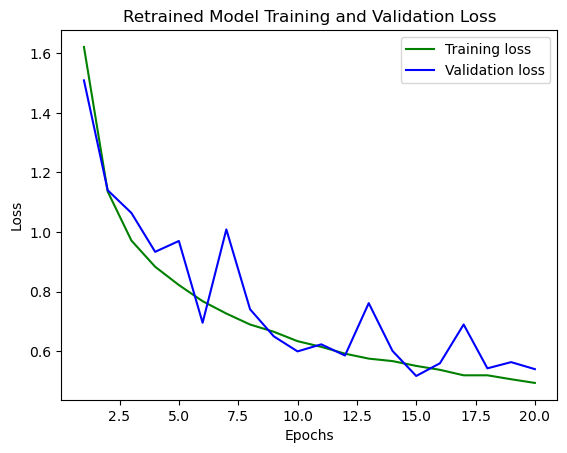

In [29]:
plt.plot(epochs1, loss_training1, 'g', label='Training loss')
plt.plot(epochs1, loss_val1, 'b', label='Validation loss')
plt.title('Retrained Model Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Retrained Model - Accuracy Vs Epochs

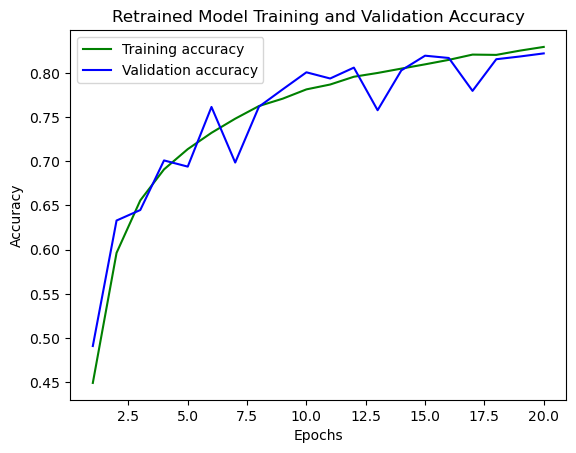

In [30]:
plt.plot(epochs1, acc_training1, 'g', label='Training accuracy')
plt.plot(epochs1, acc_val1, 'b', label='Validation accuracy')
plt.title('Retrained Model Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [31]:
# Final Evaluation of Retrained Model
retrained_loss, retrained_acc = model_retrained.evaluate(X_test, y_test_raw, verbose=2)
print(f"\nRetrained Model Test Accuracy: {retrained_acc * 100:.2f}%")
print(f"Retrained Model Test Loss: {retrained_loss:.4f}")

# Generate Predictions for Detailed Classification Report
y_pred_probs_retr = model_retrained.predict(X_test)
y_pred_retr = np.argmax(y_pred_probs_retr, axis=1)

print("\nClassification Report (Retrained Model):")
print(classification_report(y_test_raw, y_pred_retr, target_names=cifar10_classes))

313/313 - 11s - 36ms/step - accuracy: 0.8220 - loss: 0.5395

Retrained Model Test Accuracy: 82.20%
Retrained Model Test Loss: 0.5395
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step

Classification Report (Retrained Model):
              precision    recall  f1-score   support

    airplane       0.90      0.74      0.81      1000
  automobile       0.90      0.91      0.90      1000
        bird       0.80      0.69      0.74      1000
         cat       0.70      0.69      0.70      1000
        deer       0.84      0.80      0.82      1000
         dog       0.81      0.75      0.78      1000
        frog       0.79      0.93      0.85      1000
       horse       0.86      0.88      0.87      1000
        ship       0.90      0.88      0.89      1000
       truck       0.74      0.96      0.84      1000

    accuracy                           0.82     10000
   macro avg       0.83      0.82      0.82     10000
weighted avg       0.83      0.82      0.82     10000



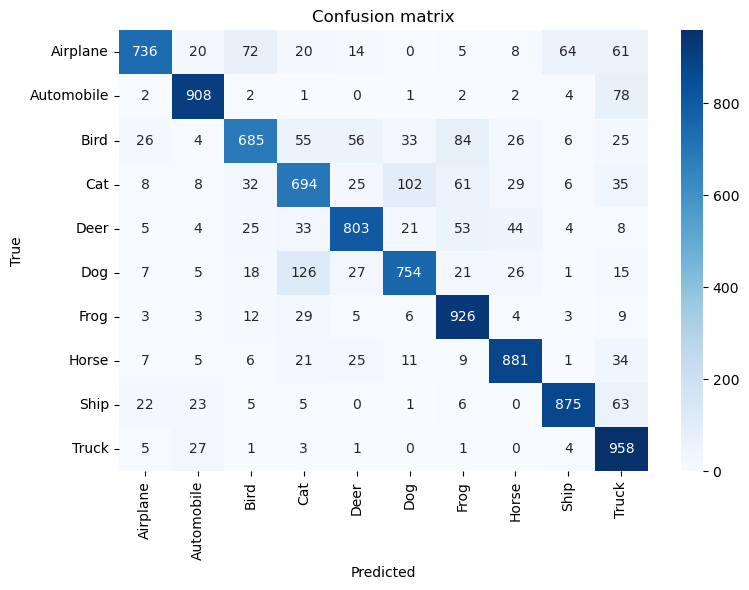

In [42]:
y_pred = np.argmax(model_retrained.predict(X_test, verbose=0), axis=1)
y_true = y_test_raw.ravel()

CLASS_NAMES = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

## Test the best performing model

|   Class Index | Label      |
|--------------:|:-----------|
|             0 | Airplane   |
|             1 | Automobile |
|             2 | Bird       |
|             3 | Cat        |
|             4 | Deer       |
|             5 | Dog        |
|             6 | Frog       |
|             7 | Horse      |
|             8 | Ship       |
|             9 | Truck      |

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


Softmax Outputs: [[1.2476540e-03 1.0025672e-03 5.3696046e-03 1.3465849e-02 1.0557941e-02
  3.7157449e-03 6.7927339e-03 9.4174492e-01 2.9899018e-05 1.6073110e-02]]


Predicted Label: 7
Confidence: 0.9417449


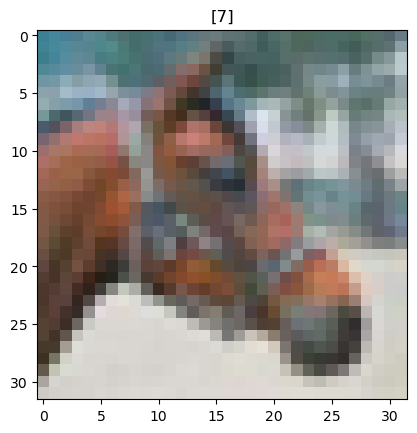

In [39]:
plt.figure
n = 17
plt.title(y_test_raw[n])
plt.imshow(X_test[n])
y_pred = model_retrained.predict(X_test[n].reshape(1,32,32,3))
print('\n')
print("Softmax Outputs:", y_pred)

for i in y_pred:
    for j, k in enumerate(i):
        if k == np.max(i):
            print("\n")
            print("Predicted Label:", labels[j])

print("Confidence:", y_pred[0][predicted_index])
# #Convert the predicted probability to labels
# labels = [0,1,2,3,4,5,6,7,8,9]
# for i in y_pred:
#     for j, k in enumerate(i):
#         if k == y_pred(max):
#             print('\n')
#             print('Predicted Label:', labels[j])